### Import Libraries

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

### Data

In [140]:
url = "Dataset/House_Price.csv"
df = pd.read_csv(url)
df.head(10)

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33
5,70,2,True,True,False,North Program Organization,2.050000e+09,68333.33
6,87,2,True,True,True,Pardis,6.000000e+08,20000.00
7,59,1,True,True,True,Shahran,2.150000e+09,71666.67
8,54,2,True,True,False,Andisheh,4.930000e+08,16433.33
9,71,1,True,True,True,West Ferdows Boulevard,2.370000e+09,79000.00


### Data Insight

In [141]:
df.shape

(3479, 8)

In [142]:
df.describe()

,Room,Price,Price(USD)
count,3479.000000,3.479000e+03,3.479000e+03
mean,2.079908,5.359023e+09,1.786341e+05
std,0.758275,8.099935e+09,2.699978e+05
min,0.000000,3.600000e+06,1.200000e+02
25%,2.000000,1.418250e+09,4.727500e+04
50%,2.000000,2.900000e+09,9.666667e+04
75%,2.000000,6.000000e+09,2.000000e+05
max,5.000000,9.240000e+10,3.080000e+06


In [143]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   str    
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   str    
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), str(2)
memory usage: 146.2 KB


In [144]:
df.nunique()

Area          243
Room            6
Parking         2
Warehouse       2
Elevator        2
Address       192
Price         934
Price(USD)    932
dtype: int64

### Data Cleaning

In [145]:
df = df.dropna(subset="Address")

In [146]:
df.isna().sum()

Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address       0
Price         0
Price(USD)    0
dtype: int64

In [147]:
numerical = ["Room", "Price", "Price(USD)"]

In [148]:
binary = ["Parking", "Warehouse", "Elevator"]

In [149]:
nominal = ["Area", "Address"]

In [150]:
# norm = StandardScaler()
# df[numerical] = norm.fit_transform(df[numerical])

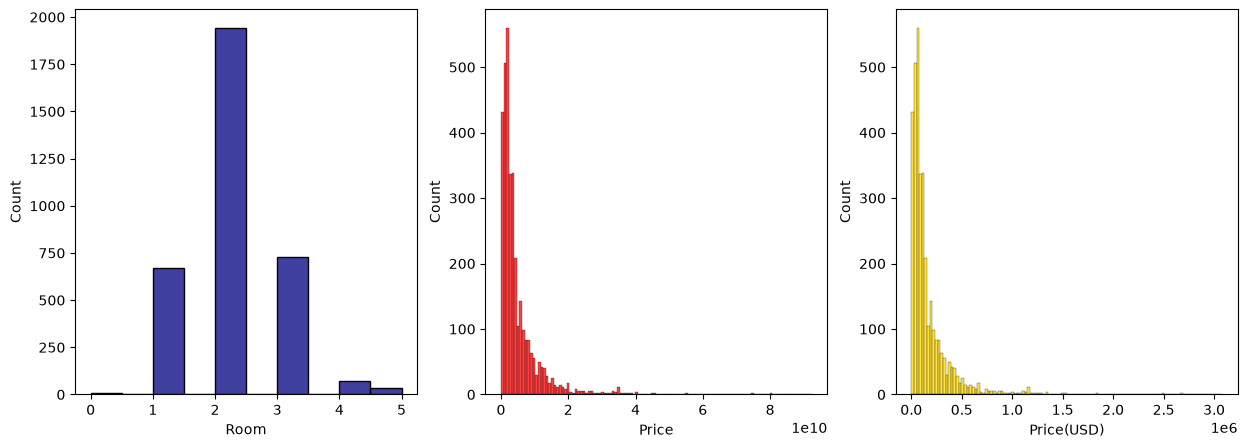

In [151]:
fig, ax1 = plt.subplots(1, 3, figsize=(15, 5))
sns.histplot(df[numerical[0]], ax=ax1[0], color="navy", bins=10)
sns.histplot(df[numerical[1]], ax=ax1[1], color="red")
sns.histplot(df[numerical[2]], ax=ax1[2], color="gold")
plt.show()

In [158]:
df[df[numerical[2]] > 1000000].count()

Area          76
Room          76
Parking       76
Warehouse     76
Elevator      76
Address       76
Price         76
Price(USD)    76
dtype: int64

In [170]:
df[df[numerical[0]]==5].count()

Area          33
Room          33
Parking       33
Warehouse     33
Elevator      33
Address       33
Price         33
Price(USD)    33
dtype: int64

In [173]:
df[df[numerical[1]]>20000000000].count()

Area          133
Room          133
Parking       133
Warehouse     133
Elevator      133
Address       133
Price         133
Price(USD)    133
dtype: int64

In [189]:
top10_idx = df[numerical[1]].nlargest(10).index
print(df.loc[top10_idx, numerical[1]])   # نمایش مقادیر
df.drop(index=top10_idx, inplace=True)   # حذف یکجا

1707    9.240000e+10
1810    9.100000e+10
430     8.500000e+10
819     8.160000e+10
1332    8.050000e+10
1694    8.000000e+10
3051    7.950000e+10
3107    7.560000e+10
831     7.500000e+10
2394    7.440000e+10
Name: Price, dtype: float64


/tmp/ipykernel_4604/1082903307.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(index=top10_idx, inplace=True)   # حذف یکجا
